# Week 2: Data Collection & Quality Assurance Pipeline
**UCI Heart Disease Databases** (Cleveland, Hungarian, Switzerland, VA Long Beach)

Companion notebook to *Week2_Data_Collection_QA_Plan.docx*. Run top to bottom.

**Stages:** 1 Acquisition → 2 Profiling → 3 Validation → 4 Cleaning → 5 Outliers → 6 Imputation → 7 Cross-site consistency → 8 Reporting

**Requirements:** `pandas numpy scipy matplotlib`

## 0. Setup and configuration
Set `DATA_DIR` to the folder containing the unzipped `processed.*.data` files.

In [1]:
import argparse
import hashlib
import json
import logging
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# --------------------------------------------------------------------------- #
# Configuration / data dictionary
# --------------------------------------------------------------------------- #
SITES = {
    "cleveland": "Cleveland Clinic Foundation (USA)",
    "hungarian": "Hungarian Institute of Cardiology (Budapest)",
    "switzerland": "University Hospital Zurich/Basel (Switzerland)",
    "va": "V.A. Medical Center Long Beach (USA)",
}
COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

# Valid domain for categorical attributes (from heart-disease.names)
CATEGORICAL_DOMAINS = {
    "sex": {0, 1}, "cp": {1, 2, 3, 4}, "fbs": {0, 1}, "restecg": {0, 1, 2},
    "exang": {0, 1}, "slope": {1, 2, 3}, "ca": {0, 1, 2, 3},
    "thal": {3, 6, 7}, "num": {0, 1, 2, 3, 4},
}
# Clinically plausible ranges for continuous attributes (hard limits)
PLAUSIBLE_RANGES = {
    "age": (18, 100), "trestbps": (60, 260), "chol": (80, 700),
    "thalach": (50, 250), "oldpeak": (0, 10),
}
NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak"]
CATEGORICAL = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s", force=True)
log = logging.getLogger("qa")

from IPython.display import display
from pathlib import Path
DATA_DIR = Path("./heart_disease")   # <-- change if needed
OUT_DIR = Path("./qa_output")
OUT_DIR.mkdir(exist_ok=True)
pd.set_option("display.width", 160)

## 1. Acquisition
Load the four processed files, parse `?` as missing, add `site` and `record_id`, and record SHA-256 hashes.

In [2]:
# --------------------------------------------------------------------------- #
def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()


def load_data(data_dir: Path):
    frames, manifest = [], []
    for site in SITES:
        path = data_dir / f"processed.{site}.data"
        df = pd.read_csv(path, header=None, names=COLUMNS, na_values=["?"])
        n_fields = pd.read_csv(path, header=None, nrows=1).shape[1]
        df["site"] = site
        df["record_id"] = [f"{site[:3].upper()}-{i:04d}" for i in range(1, len(df) + 1)]
        frames.append(df)
        manifest.append({"file": path.name, "site": SITES[site], "rows": len(df),
                         "fields_per_row": n_fields, "sha256": sha256(path)})
        log.info("Loaded %-28s rows=%d fields=%d", path.name, len(df), n_fields)
    return pd.concat(frames, ignore_index=True), pd.DataFrame(manifest)

In [3]:
raw, manifest = load_data(DATA_DIR)
manifest.to_csv(OUT_DIR / '01_file_manifest.csv', index=False)
display(manifest)
print('Total records:', len(raw))

INFO | Loaded processed.cleveland.data     rows=303 fields=14


INFO | Loaded processed.hungarian.data     rows=294 fields=14


INFO | Loaded processed.switzerland.data   rows=123 fields=14


INFO | Loaded processed.va.data            rows=200 fields=14


,file,site,rows,fields_per_row,sha256
0,processed.cleveland.data,Cleveland Clinic Foundation (USA),303,14,a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f...
1,processed.hungarian.data,Hungarian Institute of Cardiology (Budapest),294,14,d1ad108f785768cd3d7e82dc522e6f5a61eea93cccfb3a...
2,processed.switzerland.data,University Hospital Zurich/Basel (Switzerland),123,14,834a405ccf5b66ab4056bb77794adc8df0b7125186454c...
3,processed.va.data,V.A. Medical Center Long Beach (USA),200,14,e7c93d8d0d2acdadfa4c5e8de768e2191e7f618b952e29...


Total records: 920


## 2. Profiling: missing values by site (%)

In [4]:
# --------------------------------------------------------------------------- #
def missingness_table(df: pd.DataFrame) -> pd.DataFrame:
    tbl = (df.groupby("site")[COLUMNS].apply(lambda g: g.isna().mean() * 100)).T
    tbl["overall"] = df[COLUMNS].isna().mean() * 100
    return tbl.round(1)

In [5]:
miss = missingness_table(raw)
miss.to_csv(OUT_DIR / '02_missingness_by_site.csv')
display(miss.style.background_gradient(cmap='Reds', vmin=0, vmax=100))
summary = raw.groupby('site').size().rename('records').to_frame()
summary['cells_missing_%'] = raw.groupby('site')[COLUMNS].apply(lambda g: g.isna().sum().sum()/g.size*100).round(1)
display(summary)

site,cleveland,hungarian,switzerland,va,overall
age,0.000000,0.000000,0.000000,0.000000,0.000000
sex,0.000000,0.000000,0.000000,0.000000,0.000000
cp,0.000000,0.000000,0.000000,0.000000,0.000000
trestbps,0.000000,0.300000,1.600000,28.000000,6.400000
chol,0.000000,7.800000,0.000000,3.500000,3.300000
fbs,0.000000,2.700000,61.000000,3.500000,9.800000
restecg,0.000000,0.300000,0.800000,0.000000,0.200000
thalach,0.000000,0.300000,0.800000,26.500000,6.000000
exang,0.000000,0.300000,0.800000,26.500000,6.000000
oldpeak,0.000000,0.000000,4.900000,28.000000,6.700000


,records,cells_missing_%
site,,
cleveland,303,0.1
hungarian,294,19.0
switzerland,123,15.9
va,200,24.9


## 3. Validation
Rules: duplicates, categorical domains, plausible ranges, sentinel zeros, cross-field logic, structural (>90% missing).

In [6]:
# --------------------------------------------------------------------------- #
def validate(df: pd.DataFrame) -> pd.DataFrame:
    issues = []

    def add(mask, rule, severity, col):
        for _, r in df.loc[mask, ["record_id", "site"]].iterrows():
            issues.append({"record_id": r.record_id, "site": r.site, "column": col,
                           "rule": rule, "severity": severity})

    # V1 - exact duplicate rows within a site
    add(df.duplicated(subset=COLUMNS + ["site"], keep="first"),
        "Exact duplicate record", "Medium", "all")

    # V2 - categorical domain
    for col, dom in CATEGORICAL_DOMAINS.items():
        add(df[col].notna() & ~df[col].isin(dom), f"{col} outside valid domain {sorted(dom)}",
            "High", col)

    # V3 - plausible physiological range (zero is treated as a sentinel, reported separately)
    for col, (lo, hi) in PLAUSIBLE_RANGES.items():
        bad = df[col].notna() & ((df[col] < lo) | (df[col] > hi))
        add(bad, f"{col} outside plausible range [{lo},{hi}]", "High", col)

    # V4 - sentinel zeros (0 is physiologically impossible for these)
    for col in ["trestbps", "chol", "thalach"]:
        add(df[col] == 0, f"{col} = 0 (sentinel for 'not measured')", "High", col)

    # V5 - cross-field consistency
    add(df["oldpeak"] < 0, "oldpeak negative (ST depression cannot be < 0 in this coding)",
        "Medium", "oldpeak")
    add(df["thal"].notna() & ~df["thal"].isin([3, 6, 7]),
        "thal coded with non-standard value", "Medium", "thal")
    add(df["age"].notna() & df["thalach"].notna() & (df["thalach"] > (220 - df["age"]) * 1.25),
        "thalach > 125% of age-predicted maximum (220 - age)", "Low", "thalach")

    # V6 - site-level structural anomalies
    for site, g in df.groupby("site"):
        for col in COLUMNS:
            if col != "num" and g[col].isna().mean() > 0.90:
                issues.append({"record_id": f"[{site} - whole column]", "site": site,
                               "column": col, "rule": ">90% missing at this site",
                               "severity": "High"})
    return pd.DataFrame(issues)

In [7]:
issues = validate(raw)
issues.to_csv(OUT_DIR / '03_validation_issue_log.csv', index=False)
issue_summary = (issues.groupby(['site','rule','severity']).size().rename('n_records').reset_index().sort_values(['severity','n_records'], ascending=[True, False]))
issue_summary.to_csv(OUT_DIR / '03_validation_summary.csv', index=False)
print('Total rule violations flagged:', len(issues))
display(issue_summary)

Total rule violations flagged: 376


,site,rule,severity,n_records
3,switzerland,chol = 0 (sentinel for 'not measured'),High,123
4,switzerland,"chol outside plausible range [80,700]",High,123
9,va,chol = 0 (sentinel for 'not measured'),High,49
10,va,"chol outside plausible range [80,700]",High,49
6,switzerland,"oldpeak outside plausible range [0,10]",High,11
0,hungarian,>90% missing at this site,High,2
2,switzerland,>90% missing at this site,High,1
7,va,>90% missing at this site,High,1
12,va,"oldpeak outside plausible range [0,10]",High,1
13,va,trestbps = 0 (sentinel for 'not measured'),High,1


## 4. Cleaning
Drop duplicates, recode zero sentinels and negative ST depression to missing, create binary `target` (num > 0), flag variables >50% missing. Every change is logged.

In [8]:
# --------------------------------------------------------------------------- #
def clean(df: pd.DataFrame):
    out = df.copy()
    audit = []

    def log_change(action, col, n):
        if n:
            audit.append({"action": action, "column": col, "records_affected": int(n)})
            log.info("CLEAN | %-55s %-9s %4d", action, col, n)

    # C1 - remove exact duplicates
    dup = out.duplicated(subset=COLUMNS + ["site"], keep="first")
    log_change("Dropped exact duplicate record", "all", dup.sum())
    out = out.loc[~dup].copy()

    # C2 - zero sentinels -> NaN
    for col in ["trestbps", "chol", "thalach"]:
        m = out[col] == 0
        log_change("Zero sentinel recoded to missing", col, m.sum())
        out.loc[m, col] = np.nan

    # C3 - negative oldpeak -> NaN (flagged; cannot be verified against source)
    m = out["oldpeak"] < 0
    log_change("Negative ST depression recoded to missing", "oldpeak", m.sum())
    out.loc[m, "oldpeak"] = np.nan

    # C4 - target: binary presence (0 = none, 1 = any disease), keep original grade
    out["num_grade"] = out["num"]
    out["target"] = (out["num"] > 0).astype(int)

    # C5 - drop columns structurally unusable (>90% missing overall)
    overall = out[CATEGORICAL + NUMERIC].isna().mean()
    unusable = overall[overall > 0.50].index.tolist()
    audit.append({"action": "Flagged as unusable for pooled modelling (>50% missing)",
                  "column": ", ".join(unusable), "records_affected": len(out)})
    log.info("CLEAN | Columns >50%% missing overall: %s", unusable)
    return out, pd.DataFrame(audit), unusable

In [9]:
cleaned, audit, unusable = clean(raw)
audit.to_csv(OUT_DIR / '04_cleaning_audit_log.csv', index=False)
display(audit)
print('Unusable for pooled modelling:', unusable)

INFO | CLEAN | Dropped exact duplicate record                          all          2


INFO | CLEAN | Zero sentinel recoded to missing                        trestbps     1


INFO | CLEAN | Zero sentinel recoded to missing                        chol       172


INFO | CLEAN | Negative ST depression recoded to missing               oldpeak     12


INFO | CLEAN | Columns >50% missing overall: ['ca', 'thal']


,action,column,records_affected
0,Dropped exact duplicate record,all,2
1,Zero sentinel recoded to missing,trestbps,1
2,Zero sentinel recoded to missing,chol,172
3,Negative ST depression recoded to missing,oldpeak,12
4,Flagged as unusable for pooled modelling (>50%...,"ca, thal",918


Unusable for pooled modelling: ['ca', 'thal']


## 5. Outlier flagging (Tukey 1.5 × IQR)
Outliers are flagged, not removed.

In [10]:
# --------------------------------------------------------------------------- #
def flag_outliers(df: pd.DataFrame):
    res, flags = [], pd.DataFrame(index=df.index)
    for col in NUMERIC:
        q1, q3 = df[col].quantile([.25, .75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        flags[f"{col}_outlier"] = (df[col] < lo) | (df[col] > hi)
        res.append({"variable": col, "lower_fence": round(lo, 1), "upper_fence": round(hi, 1),
                    "n_outliers": int(flags[f"{col}_outlier"].sum()),
                    "pct": round(flags[f"{col}_outlier"].mean() * 100, 1)})
    return pd.DataFrame(res), flags

In [11]:
out_tbl, flags = flag_outliers(cleaned)
out_tbl.to_csv(OUT_DIR / '05_outlier_summary.csv', index=False)
display(out_tbl)

,variable,lower_fence,upper_fence,n_outliers,pct
0,age,27.5,79.5,0,0.0
1,trestbps,90.0,170.0,27,2.9
2,chol,109.5,377.5,23,2.5
3,thalach,64.5,212.5,2,0.2
4,oldpeak,-2.2,3.8,15,1.6


## 6. Imputation (within-site median / mode + missing indicators)
Single imputation is for data preparation only; use multiple imputation (MICE) at the modelling stage.

In [12]:
# --------------------------------------------------------------------------- #
def impute(df: pd.DataFrame, unusable):
    out = df.copy()
    usable_num = [c for c in NUMERIC]
    usable_cat = [c for c in CATEGORICAL if c not in unusable]
    # missingness indicators preserve information about "not measured"
    for col in usable_num + usable_cat:
        out[f"{col}_missing"] = out[col].isna().astype(int)
    for col in usable_num:
        # site median where the site measured it; otherwise pooled median of measuring sites
        site_med = out.groupby("site")[col].transform("median")
        out[col] = out[col].fillna(site_med).fillna(out[col].median())
    for col in usable_cat:
        out[col] = out[col].fillna(out[col].mode().iloc[0])
    return out

In [13]:
imputed = impute(cleaned, unusable)
imputed = pd.concat([imputed, flags], axis=1)
imputed.to_csv(OUT_DIR / 'heart_disease_clean.csv', index=False)
chk = []
for col in NUMERIC:
    b, a = cleaned[col].dropna(), imputed[col]
    chk.append({'variable': col, 'mean_before': round(b.mean(),2), 'mean_after': round(a.mean(),2), 'sd_before': round(b.std(),2), 'sd_after': round(a.std(),2), 'ks_stat': round(stats.ks_2samp(b,a).statistic,3)})
chk = pd.DataFrame(chk); chk.to_csv(OUT_DIR / '06_imputation_check.csv', index=False)
display(chk)

,variable,mean_before,mean_after,sd_before,sd_after,ks_stat
0,age,53.51,53.51,9.43,9.43,0.000
1,trestbps,132.29,132.13,18.53,17.93,0.028
2,chol,246.87,244.71,58.56,51.97,0.104
3,thalach,137.54,136.51,25.94,25.48,0.042
4,oldpeak,0.91,0.94,1.07,1.04,0.039


## 7. Cross-site consistency
Kruskal-Wallis (continuous) and chi-square (categorical) tests of differences between hospitals.

In [14]:
# --------------------------------------------------------------------------- #
def heterogeneity(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for col in NUMERIC:
        groups = [g[col].dropna().values for _, g in df.groupby("site") if g[col].notna().sum() > 5]
        if len(groups) > 1:
            h, p = stats.kruskal(*groups)
            rows.append({"variable": col, "test": "Kruskal-Wallis", "statistic": round(h, 2),
                         "p_value": p, "n_sites": len(groups)})
    for col in ["sex", "cp", "fbs", "restecg", "exang", "target"]:
        ct = pd.crosstab(df["site"], df[col])
        if ct.shape[0] > 1 and ct.shape[1] > 1:
            chi2, p, _, _ = stats.chi2_contingency(ct)
            rows.append({"variable": col, "test": "Chi-square", "statistic": round(chi2, 2),
                         "p_value": p, "n_sites": ct.shape[0]})
    out = pd.DataFrame(rows)
    out["significant_(p<0.05)"] = out["p_value"] < 0.05
    return out

In [15]:
het = heterogeneity(cleaned)
het.to_csv(OUT_DIR / '07_cross_site_heterogeneity.csv', index=False)
display(het.style.format({'p_value': '{:.2e}'}))
print(f"{het['significant_(p<0.05)'].sum()} of {len(het)} variables differ significantly across sites")

,variable,test,statistic,p_value,n_sites,significant_(p<0.05)
0,age,Kruskal-Wallis,201.040000,2.52e-43,4,True
1,trestbps,Kruskal-Wallis,5.150000,1.61e-01,4,False
2,chol,Kruskal-Wallis,2.530000,2.83e-01,3,False
3,thalach,Kruskal-Wallis,160.850000,1.20e-34,4,True
4,oldpeak,Kruskal-Wallis,68.670000,8.23e-15,4,True
5,sex,Chi-square,80.180000,2.80e-17,4,True
6,cp,Chi-square,123.910000,2.11e-22,4,True
7,fbs,Chi-square,69.770000,4.77e-15,4,True
8,restecg,Chi-square,351.220000,8.44e-73,4,True
9,exang,Chi-square,55.000000,6.85e-12,4,True


9 of 11 variables differ significantly across sites


## 8. Figures and QA scorecard

In [16]:
# --------------------------------------------------------------------------- #
def make_figures(raw, cleaned, miss, out_dir: Path):
    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

    # Fig 1 - missingness heatmap
    fig, ax = plt.subplots(figsize=(7.2, 5.2))
    data = miss.drop(columns="overall").loc[COLUMNS]
    im = ax.imshow(data.values, cmap="Reds", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(data.shape[1]))
    ax.set_xticklabels([s.capitalize() for s in data.columns])
    ax.set_yticks(range(data.shape[0]))
    ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data.values[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center",
                    color="white" if v > 55 else "black", fontsize=8)
    ax.set_title("Missing values (%) by attribute and source site")
    fig.colorbar(im, ax=ax, label="% missing")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "fig1_missingness_heatmap.png", dpi=180)
    plt.close(fig)

    # Fig 2 - cholesterol before cleaning (shows zero sentinel)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=False)
    for site, g in raw.groupby("site"):
        axes[0].hist(g["chol"].dropna(), bins=30, alpha=.55, label=site.capitalize())
    axes[0].set_title("Serum cholesterol - RAW")
    axes[0].set_xlabel("mg/dl")
    axes[0].legend(frameon=False)
    for site, g in cleaned.groupby("site"):
        if g["chol"].notna().sum():
            axes[1].hist(g["chol"].dropna(), bins=30, alpha=.55, label=site.capitalize())
    axes[1].set_title("Serum cholesterol - CLEANED")
    axes[1].set_xlabel("mg/dl")
    axes[1].legend(frameon=False)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "fig2_cholesterol_before_after.png", dpi=180)
    plt.close(fig)

    # Fig 3 - boxplots by site for key numerics (cleaned, pre-imputation)
    fig, axes = plt.subplots(1, 4, figsize=(11, 3.4))
    for ax, col in zip(axes, ["age", "trestbps", "thalach", "oldpeak"]):
        data = [g[col].dropna().values for _, g in cleaned.groupby("site")]
        ax.boxplot(data, tick_labels=[s[:4].capitalize() for s in cleaned["site"].unique()],
                   showfliers=True, flierprops={"markersize": 3})
        ax.set_title(col)
    fig.suptitle("Distribution of key numeric variables by site (after cleaning)", y=1.02)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "fig3_boxplots_by_site.png", dpi=180, bbox_inches="tight")
    plt.close(fig)

    # Fig 4 - target prevalence by site
    prev = cleaned.groupby("site")["target"].mean() * 100
    fig, ax = plt.subplots(figsize=(5.5, 3.4))
    bars = ax.bar([s.capitalize() for s in prev.index], prev.values, color="#2F6B8F")
    for b, v in zip(bars, prev.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.0f}%", ha="center")
    ax.set_ylabel("% with angiographic disease (num > 0)")
    ax.set_title("Disease prevalence differs sharply by site")
    ax.set_ylim(0, 100)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "fig4_target_prevalence.png", dpi=180)
    plt.close(fig)

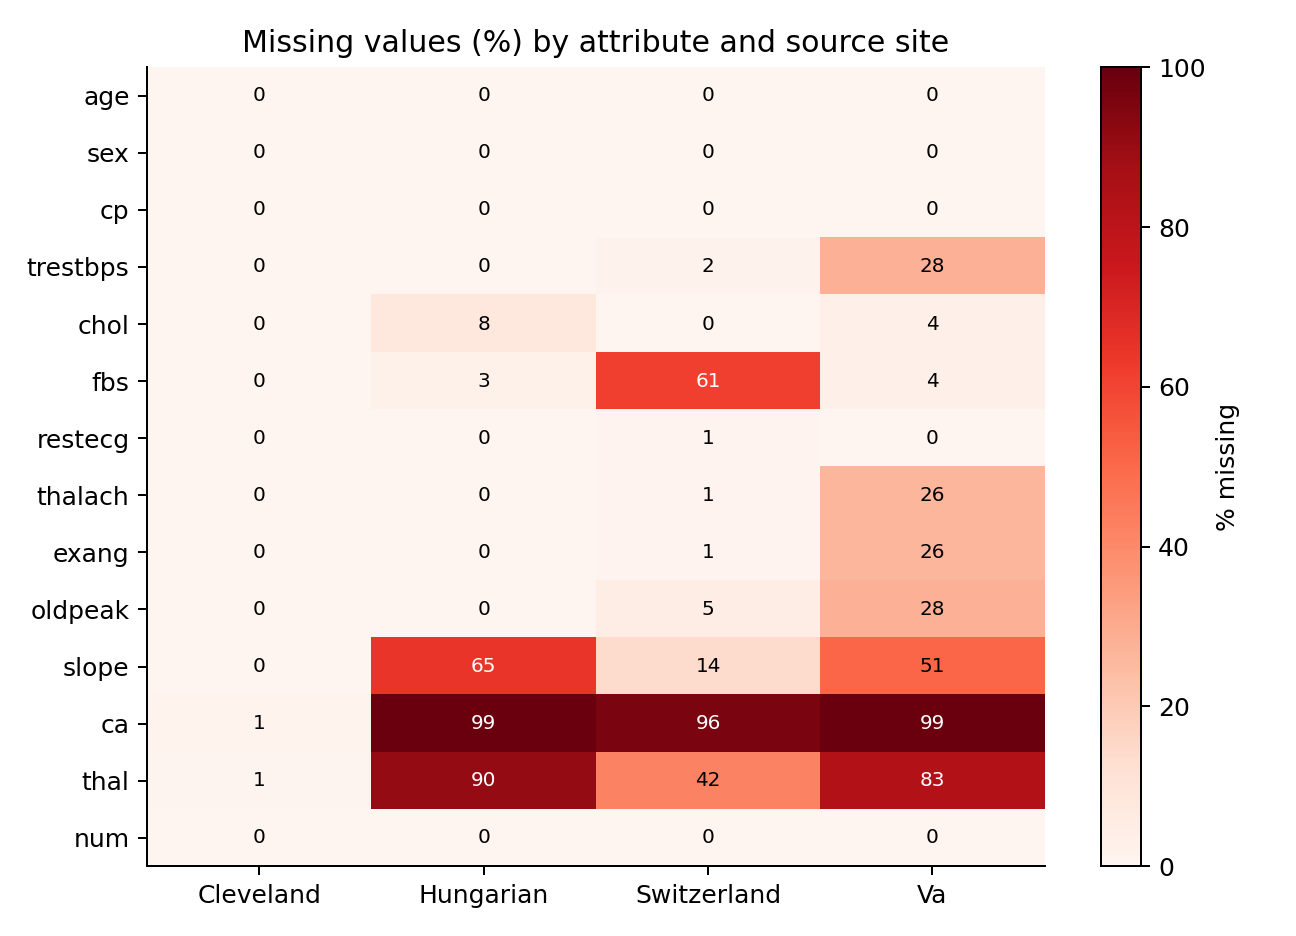

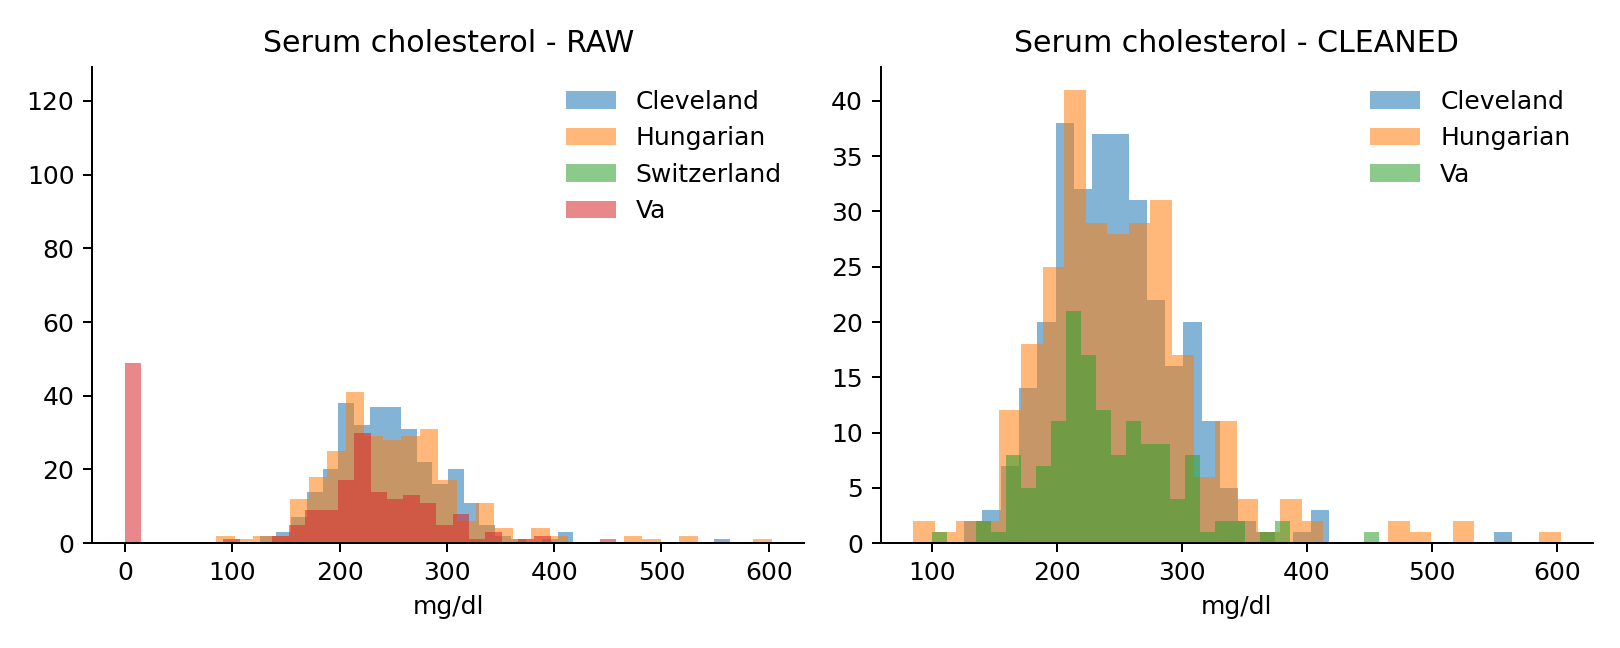

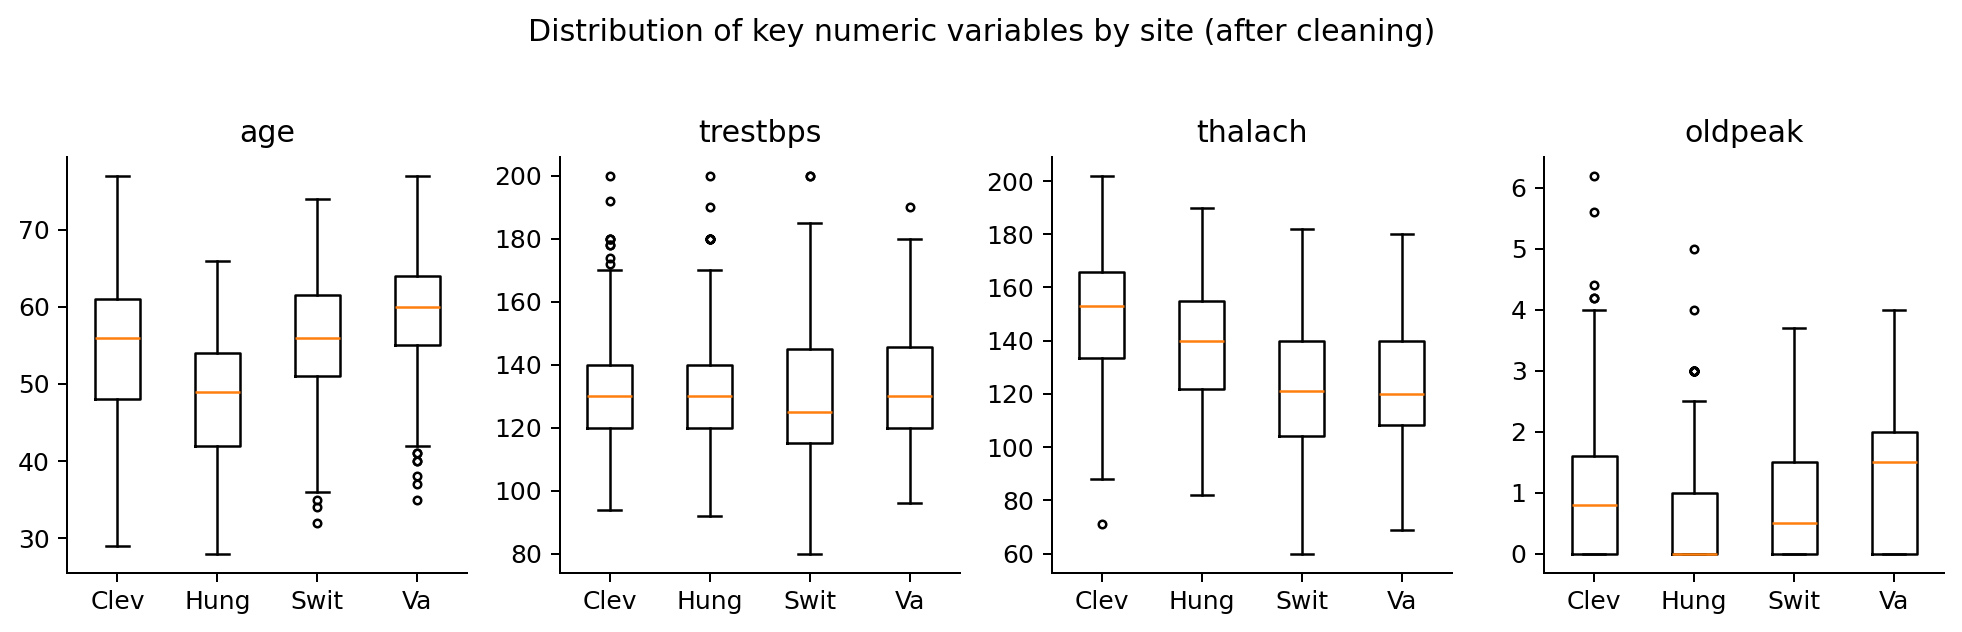

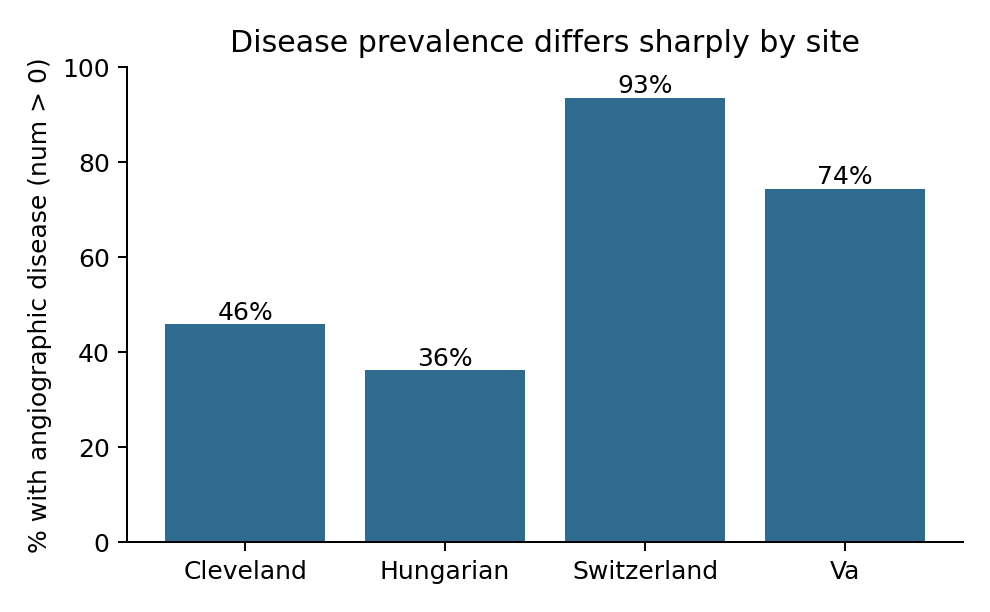

In [17]:
make_figures(raw, cleaned, miss, OUT_DIR)
from IPython.display import Image
for f in ['fig1_missingness_heatmap','fig2_cholesterol_before_after','fig3_boxplots_by_site','fig4_target_prevalence']:
    display(Image(filename=str(OUT_DIR / f'{f}.png')))

In [18]:
import json
scorecard = {
    'records_raw': int(len(raw)), 'records_clean': int(len(cleaned)),
    'duplicates_removed': int(len(raw) - len(cleaned)),
    'validation_flags_total': int(len(issues)),
    'columns_unusable_pooled': unusable,
    'completeness_raw_%': round(100 - raw[COLUMNS].isna().sum().sum()/raw[COLUMNS].size*100, 1),
    'completeness_clean_pre_imputation_%': round(100 - cleaned[COLUMNS].isna().sum().sum()/cleaned[COLUMNS].size*100, 1),
}
json.dump(scorecard, open(OUT_DIR / 'qa_scorecard.json', 'w'), indent=2)
print(json.dumps(scorecard, indent=2))
prev = cleaned.groupby('site')['target'].agg(n='size', diseased='sum', prevalence='mean').round(3)
display(prev)

{
  "records_raw": 920,
  "records_clean": 918,
  "duplicates_removed": 2,
  "validation_flags_total": 376,
  "columns_unusable_pooled": [
    "ca",
    "thal"
  ],
  "completeness_raw_%": 86.3,
  "completeness_clean_pre_imputation_%": 84.9
}


,n,diseased,prevalence
site,,,
cleveland,303,139,0.459
hungarian,293,106,0.362
switzerland,123,115,0.935
va,199,148,0.744


## Key takeaways
- Cholesterol recorded as **0** at Switzerland (all rows) and VA (49 rows) is a missing-value code, not data.
- `ca` and `thal` are >50% missing and excluded from pooled modelling.
- Disease prevalence differs strongly by site, so site must be a covariate or a stratification variable.
- Outliers are flagged, not removed; move to multiple imputation at the modelling stage.